<a href="https://colab.research.google.com/github/ZidAvwa/PCVK_Ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Object Detection


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**D1.1 - Import the libraries**

---

In [2]:
import os
import re
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

Paths and helper functions. `find_image()` finds an image by name anywhere in `Images`, ignoring case, spaces, `-` and `_`; a full path also works. Change `BASE` if your Drive folder is different.

In [3]:
BASE = '/content/drive/MyDrive/PCVK Semester 5'
IMAGES = BASE + '/Images'
FACEDET = IMAGES + '/facedet'
HAAR = IMAGES + '/haarcascades'
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def _norm(s):
    return re.sub(r'[^a-z0-9]', '', s.lower())

def find_image(name, folder=IMAGES):
    target = _norm(os.path.splitext(name)[0])
    files = [os.path.join(d, f) for d, _, fs in os.walk(folder) for f in fs if f.lower().endswith(IMG_EXT)]
    for p in files:
        if _norm(os.path.splitext(os.path.basename(p))[0]) == target:
            return p
    for p in files:
        if target in _norm(os.path.basename(p)):
            return p
    raise FileNotFoundError("'%s' is not found in %s. Files there: %s" % (name, folder, [os.path.basename(f) for f in files]))

def read_image(name_or_path, flag=cv.IMREAD_COLOR, folder=IMAGES):
    path = name_or_path if os.path.isfile(name_or_path) else find_image(name_or_path, folder)
    img = cv.imread(path, flag)
    if img is None:
        raise FileNotFoundError('Image cannot be read: ' + path)
    print('read:', path, img.shape)
    return img

def to_rgb(img):
    return cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img

def show_row(images, titles, figsize=(14, 5), axis=True):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(to_rgb(im), None if im.ndim == 3 else 'gray')
        plt.title(t)
        if not axis:
            plt.xticks([]), plt.yticks([])
    plt.tight_layout()
    plt.show()

**D1.2 - Template matching with OpenCV (6 methods)**

---

`cv.matchTemplate()` slides the template over the image and scores every position. For the two `SQDIFF` methods the best match is the minimum of the result, for the others the maximum.

read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/cats_and_bunnies.jpg (829, 1024, 3)
read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/cat2_templatejpg.jpg (449, 356)


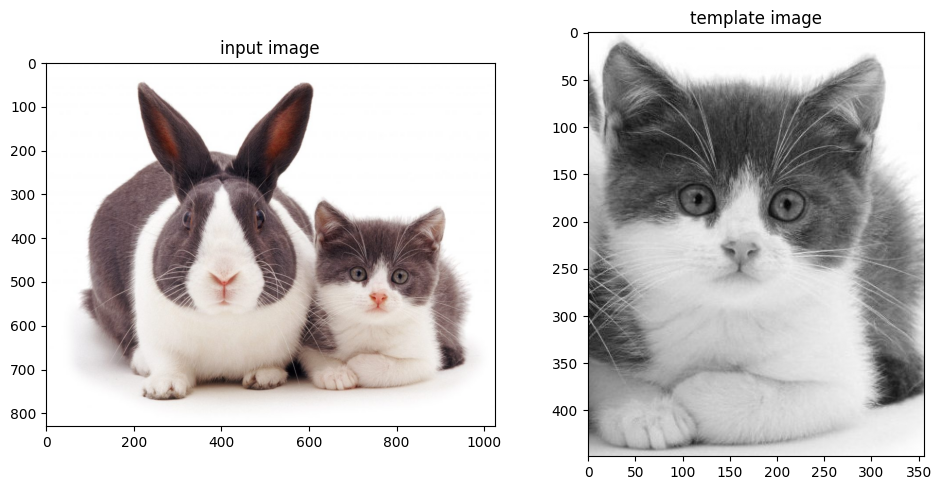

In [4]:
img_bgr = read_image('cats_and_bunnies')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
template = read_image('cat2_template', cv.IMREAD_GRAYSCALE)
h, w = template.shape

show_row([img_bgr, template], ['input image', 'template image'], (10, 5))

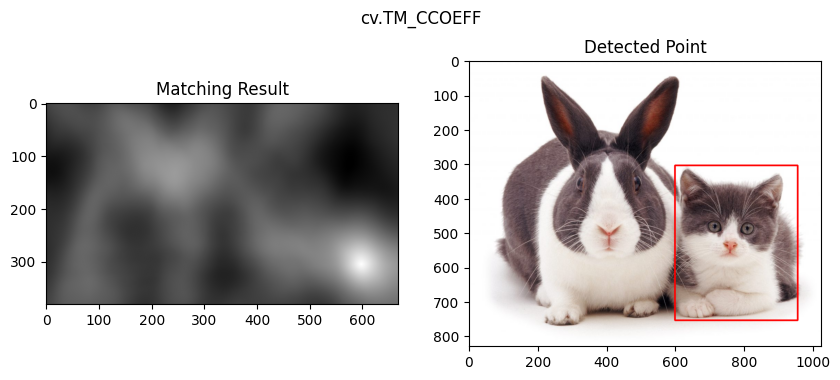

TM_CCOEFF          best position (x, y) = (597, 305)


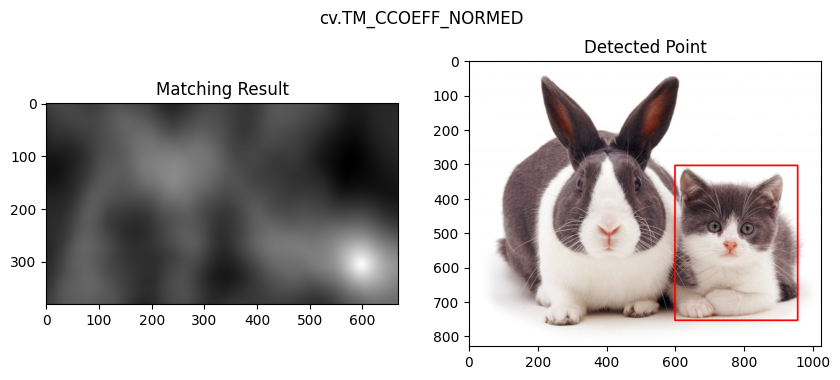

TM_CCOEFF_NORMED   best position (x, y) = (597, 305)


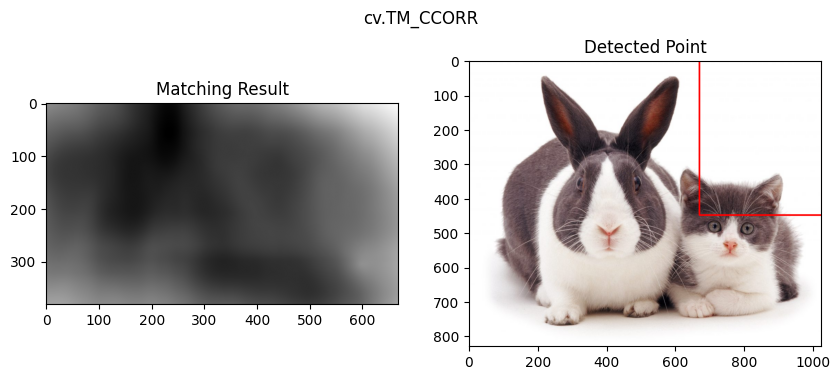

TM_CCORR           best position (x, y) = (668, 0)


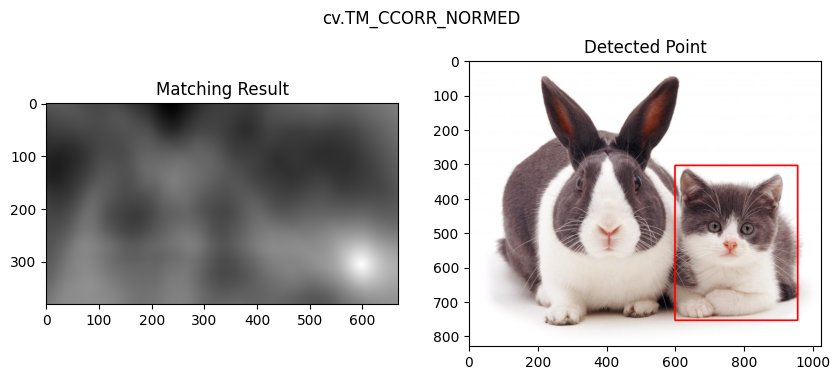

TM_CCORR_NORMED    best position (x, y) = (597, 305)


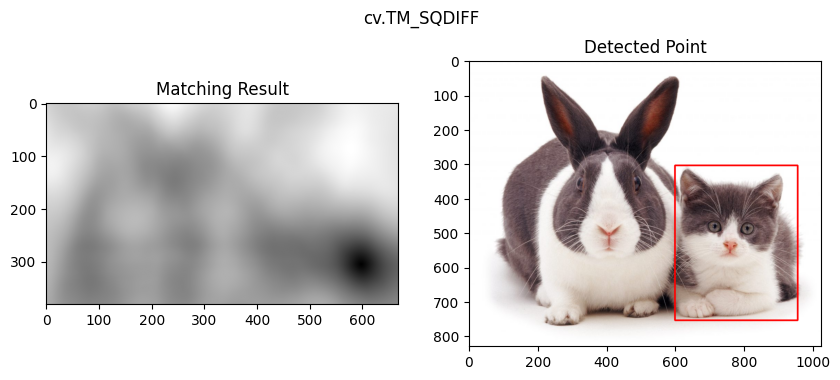

TM_SQDIFF          best position (x, y) = (597, 305)


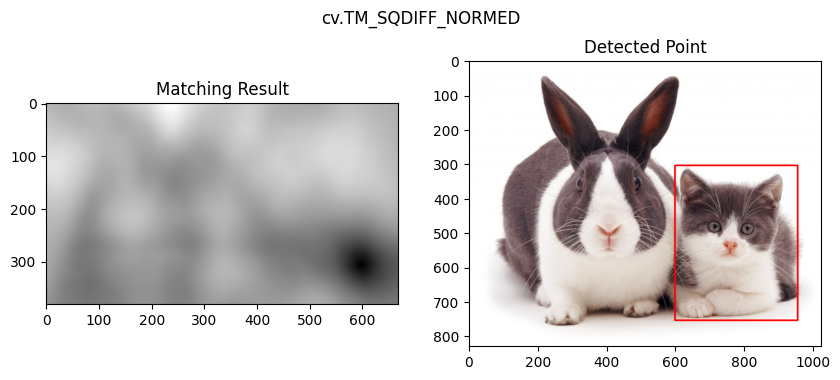

TM_SQDIFF_NORMED   best position (x, y) = (597, 305)


In [5]:
methods = ['TM_CCOEFF', 'TM_CCOEFF_NORMED', 'TM_CCORR', 'TM_CCORR_NORMED', 'TM_SQDIFF', 'TM_SQDIFF_NORMED']

for name in methods:
    method = getattr(cv, name)
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    top_left = min_loc if method in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED) else max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    detected = img_bgr.copy()
    cv.rectangle(detected, top_left, bottom_right, (0, 0, 255), 4)

    plt.figure(figsize=(10, 4))
    plt.suptitle('cv.' + name)
    plt.subplot(121), plt.imshow(res, 'gray'), plt.title('Matching Result')
    plt.subplot(122), plt.imshow(to_rgb(detected)), plt.title('Detected Point')
    plt.show()
    print('%-18s best position (x, y) = %s' % (name, top_left))

**Observation (D1.2)** - Five of the six methods give the same box, with the top-left corner at (597, 305), exactly on the kitten. `TM_CCORR` fails: its best position is (668, 0), a box in the white top-right corner, because plain correlation is not normalised and bright areas give large values whatever their content. The two `SQDIFF` methods show the match as a dark spot in the result image, the other methods as a bright spot.

**D1.3 - Template matching without OpenCV for multiple objects**

---

Only NumPy is used. Every window of the image is compared with the template by zero-mean normalised cross-correlation (the same score as `TM_CCOEFF_NORMED`). Positions above `THRESHOLD` are candidates, and non-maximum suppression keeps one box per object.

In [6]:
def ncc_map(image, templ):
    I = image.astype(np.float32)
    T0 = templ.astype(np.float32)
    T0 = T0 - T0.mean()
    t_norm = np.sqrt((T0 ** 2).sum())
    th, tw = T0.shape
    R = np.zeros((I.shape[0] - th + 1, I.shape[1] - tw + 1), dtype=np.float32)
    for y in range(R.shape[0]):
        windows = sliding_window_view(I[y:y + th], (th, tw))[0]
        w0 = windows - windows.mean(axis=(1, 2), keepdims=True)
        num = (w0 * T0).sum(axis=(1, 2))
        den = np.sqrt((w0 ** 2).sum(axis=(1, 2))) * t_norm
        R[y] = num / (den + 1e-9)
    return R

def pick_peaks(R, threshold, tsize):
    th, tw = tsize
    ys, xs = np.where(R >= threshold)
    order = np.argsort(R[ys, xs])[::-1]
    picked = []
    for i in order:
        y, x = ys[i], xs[i]
        if all(abs(y - py) >= th // 2 or abs(x - px) >= tw // 2 for py, px in picked):
            picked.append((y, x))
    return picked

read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/bahrain.jpg (586, 596, 3)
read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/bahrain-template.jpg (73, 88)


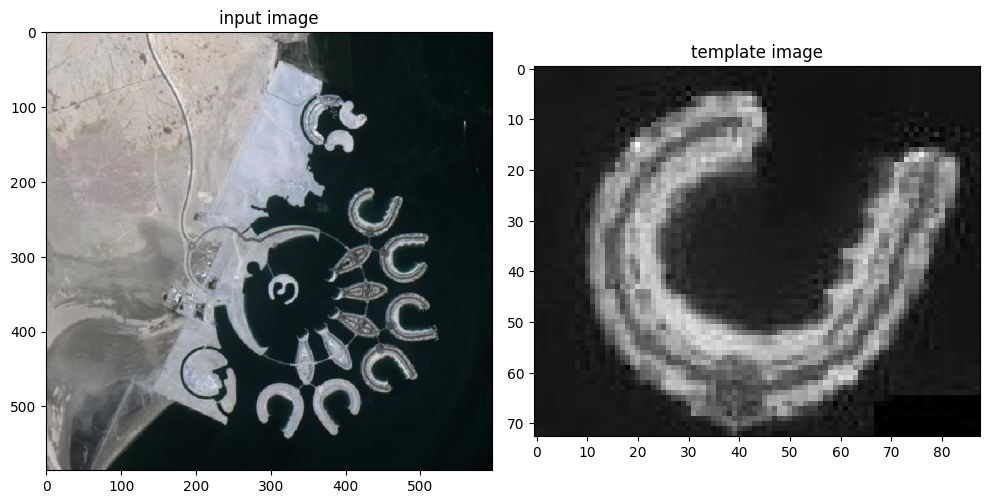

R shape: (514, 509) | max score: 0.964


In [7]:
bahrain = read_image('bahrain')
bahrain_gray = cv.cvtColor(bahrain, cv.COLOR_BGR2GRAY)
b_template = read_image('bahrain-template', cv.IMREAD_GRAYSCALE)
th, tw = b_template.shape

show_row([bahrain, b_template], ['input image', 'template image'], (10, 5))

R = ncc_map(bahrain_gray, b_template)
print('R shape:', R.shape, '| max score: %.3f' % R.max())

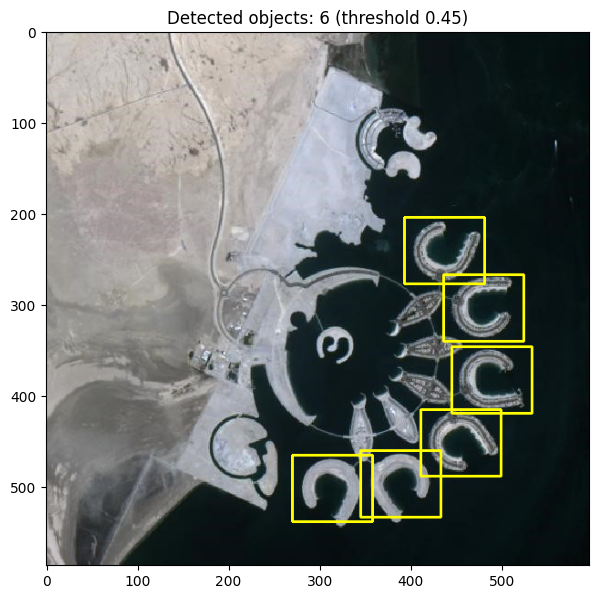

In [8]:
THRESHOLD = 0.45

peaks = pick_peaks(R, THRESHOLD, (th, tw))
result = bahrain.copy()
for (y, x) in peaks:
    cv.rectangle(result, (x, y), (x + tw, y + th), (0, 255, 255), 2)

plt.figure(figsize=(7, 7))
plt.imshow(to_rgb(result))
plt.title('Detected objects: %d (threshold %.2f)' % (len(peaks), THRESHOLD))
plt.show()

In [9]:
R_cv = cv.matchTemplate(bahrain_gray, b_template, cv.TM_CCOEFF_NORMED)
print('max absolute difference to OpenCV:', float(np.abs(R - R_cv).max()))

max absolute difference to OpenCV: 4.194490611553192e-05


**Observation (D1.3)** - The manual score map is the same as OpenCV (maximum difference 4e-5), and the best score is 0.964. With `THRESHOLD = 0.6` only 1 shape was detected, because the other shapes differ a little from the template in size and brightness and score lower. The threshold is lowered to 0.45 so that more shapes are found; run the cell again and change the value until the boxes cover the shapes and no wrong box appears.

**D1.4 - Edge detection: Sobel, Canny and Laplacian**

---

In [10]:
park = read_image('car-park')
park_gray = cv.cvtColor(park, cv.COLOR_BGR2GRAY)
park_blur = cv.GaussianBlur(park_gray, (5, 5), 0)

read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/car-park.jpg (619, 1100, 3)


**a. Sobel** - gradient in x and y, and the combined magnitude.

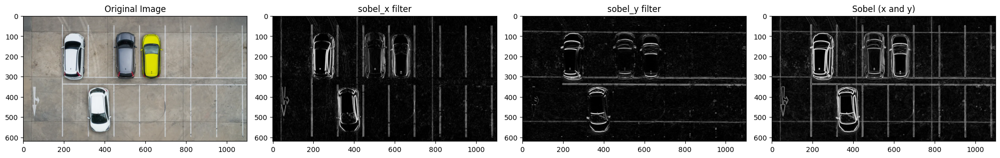

In [11]:
sobel_x = cv.Sobel(park_blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(park_blur, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(cv.magnitude(sobel_x, sobel_y))

show_row([park, cv.convertScaleAbs(sobel_x), cv.convertScaleAbs(sobel_y), sobel],
         ['Original Image', 'sobel_x filter', 'sobel_y filter', 'Sobel (x and y)'], (20, 4))

**b. Canny** - smoothing, gradient, non-maximum suppression, hysteresis (100 / 200).

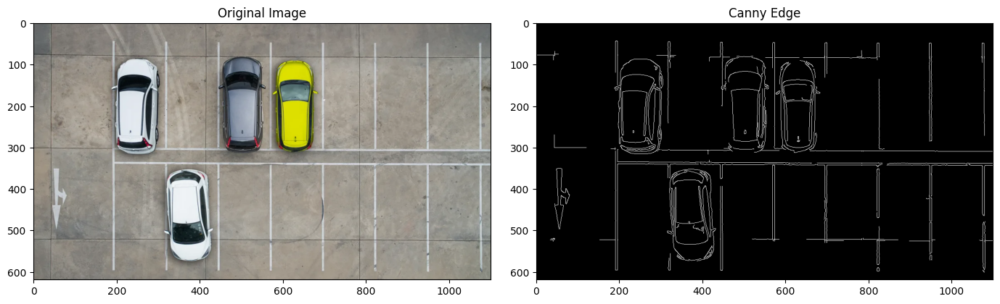

In [12]:
canny = cv.Canny(park_blur, 100, 200)

show_row([park, canny], ['Original Image', 'Canny Edge'], (14, 4))

**c. Laplacian** - second derivative, very sensitive to noise, so the image is smoothed first.

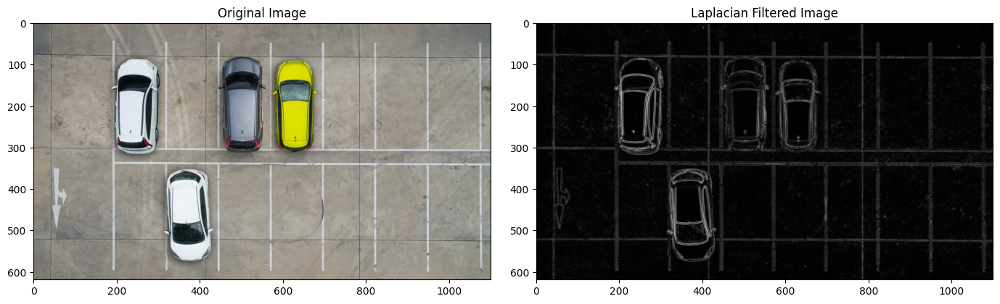

In [13]:
laplacian = cv.convertScaleAbs(cv.Laplacian(park_blur, cv.CV_64F, ksize=3))

show_row([park, laplacian], ['Original Image', 'Laplacian Filtered Image'], (14, 4))

**Observation (D1.4)** - Sobel x shows the vertical edges (parking lines, sides of the cars), Sobel y the horizontal ones, and the combined image shows both. Canny gives thin, clean outlines of the four cars, the arrow and the lane lines, with only a few noise dots. Laplacian also gives thin outlines, but they are weak and the ground texture appears as speckle, which shows its sensitivity to noise. Canny is the clearest of the three.

**D1.5 - Corner detection: Harris and Shi-Tomasi**

---

In [14]:
chess = read_image('chessboard')
chess_gray = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/chess-board.jpg (800, 1000, 3)


**a. Harris** - a pixel is a corner when its response is above 1% of the maximum.

Harris corner pixels: 2238


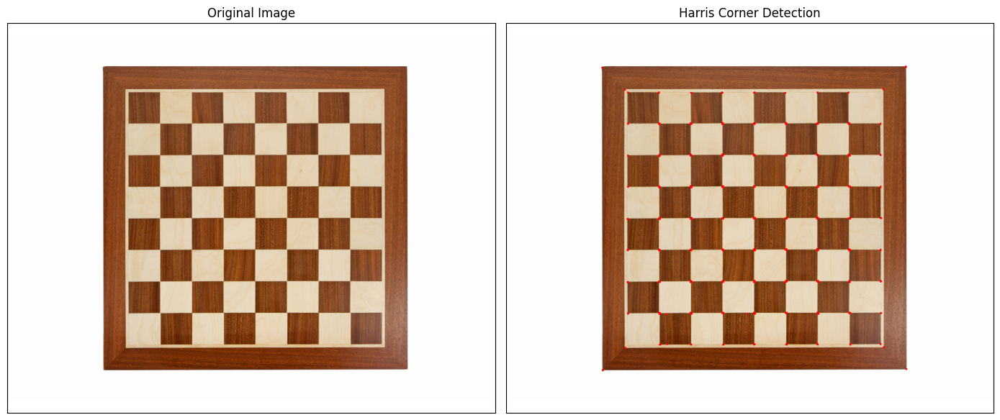

In [15]:
harris = cv.cornerHarris(np.float32(chess_gray), 2, 3, 0.04)
harris = cv.dilate(harris, None)

harris_img = chess.copy()
harris_img[harris > 0.01 * harris.max()] = [0, 0, 255]

print('Harris corner pixels:', int((harris > 0.01 * harris.max()).sum()))
show_row([chess, harris_img], ['Original Image', 'Harris Corner Detection'], (14, 7), axis=False)

**b. Shi-Tomasi** - `cv.goodFeaturesToTrack()` returns the N strongest corners.

Shi-Tomasi corners: 100


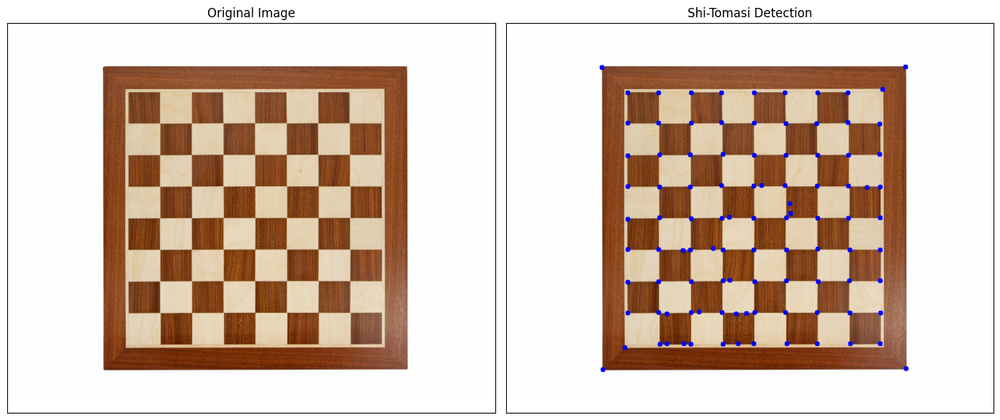

In [16]:
corners = cv.goodFeaturesToTrack(chess_gray, 100, 0.01, 10)
corners = np.int32(corners).reshape(-1, 2)

shi_img = chess.copy()
for x, y in corners:
    cv.circle(shi_img, (int(x), int(y)), 5, (255, 0, 0), -1)

print('Shi-Tomasi corners:', len(corners))
show_row([chess, shi_img], ['Original Image', 'Shi-Tomasi Detection'], (14, 7), axis=False)

**Observation (D1.5)** - Harris marks the corners with small red dots (2238 pixels) at almost all the intersections of the board, including the corners of the frame. Shi-Tomasi returns exactly 100 points. Most are on the corners, but some are placed between corners (several in the lower half) and some corners get no point, because the number of points is limited to 100 and the minimum distance is 10 px.

**D1.6 - Grid detection with the Hough transform**

---

Steps: Canny, dilation (join the double edges), erosion (thin the lines), `cv.HoughLines()`, merge similar lines.

read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/sudoku.jpg (375, 500, 3)


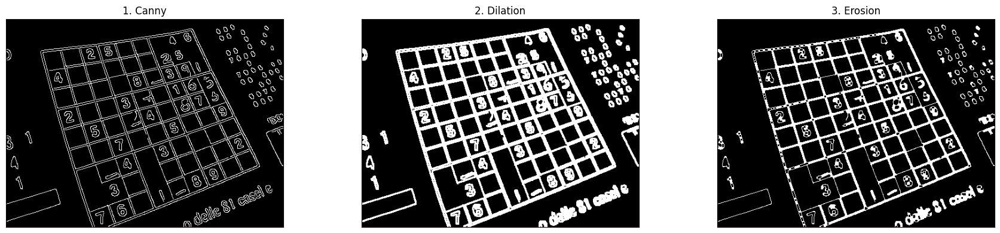

In [17]:
sudoku = read_image('sudoku')
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

edges = cv.Canny(cv.GaussianBlur(sudoku_gray, (5, 5), 0), 50, 150)
se = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
edges_d = cv.dilate(edges, se, iterations=1)
edges_e = cv.erode(edges_d, se, iterations=1)

show_row([edges, edges_d, edges_e], ['1. Canny', '2. Dilation', '3. Erosion'], (18, 4), axis=False)

lines before merging: 164
lines after merging : 29


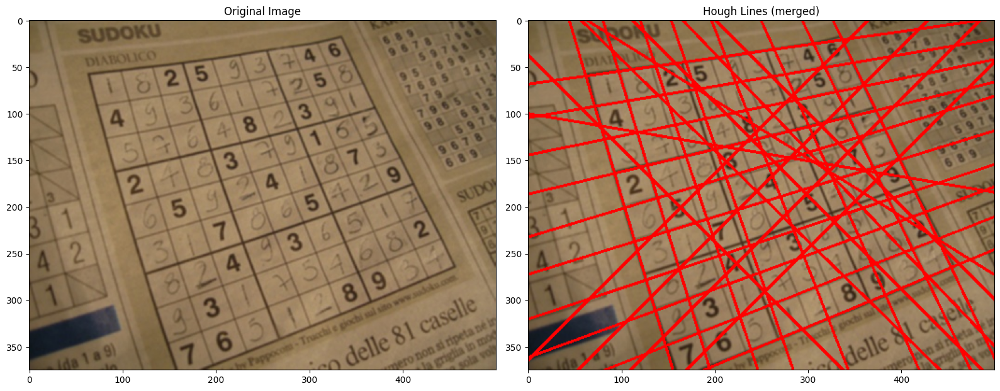

In [18]:
HOUGH_THRESHOLD = 150

lines = cv.HoughLines(edges_e, 1, np.pi / 180, HOUGH_THRESHOLD)
lines = [] if lines is None else lines[:, 0, :]
print('lines before merging:', len(lines))

def merge_lines(lines, d_rho=20, d_theta=np.deg2rad(10)):
    norm = []
    for rho, theta in lines:
        if rho < 0:
            rho, theta = -rho, theta + np.pi
        norm.append((rho, theta))
    groups = []
    for rho, theta in sorted(norm):
        for g in groups:
            g_rho = np.mean([r for r, _ in g])
            g_theta = np.arctan2(np.mean([np.sin(t) for _, t in g]), np.mean([np.cos(t) for _, t in g]))
            diff = np.abs(np.angle(np.exp(1j * (theta - g_theta))))
            if abs(rho - g_rho) < d_rho and diff < d_theta:
                g.append((rho, theta))
                break
        else:
            groups.append([(rho, theta)])
    merged = []
    for g in groups:
        rho = np.mean([r for r, _ in g])
        theta = np.arctan2(np.mean([np.sin(t) for _, t in g]), np.mean([np.cos(t) for _, t in g]))
        merged.append((rho, theta))
    return merged

merged = merge_lines(lines)
print('lines after merging :', len(merged))

hough_img = sudoku.copy()
for rho, theta in merged:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 - 3000 * b), int(y0 + 3000 * a))
    p2 = (int(x0 + 3000 * b), int(y0 - 3000 * a))
    cv.line(hough_img, p1, p2, (0, 0, 255), 2)

show_row([sudoku, hough_img], ['Original Image', 'Hough Lines (merged)'], (16, 6))

**Observation (D1.6)** - Canny finds the grid lines but also the digits and the printed text; dilation joins the double edges into thick lines and erosion thins them again. Hough found 164 lines, which became 29 after merging. The lines follow the tilted grid, but many extra lines are drawn across the digits and the text. A higher `HOUGH_THRESHOLD` removes the weak lines.

**D1.7 - Contour detection with `findContours()`**

---

Steps: binary image (Canny + dilation), `cv.findContours()`, `cv.drawContours()`. Contours smaller than `MIN_AREA` are ignored.

read: /content/drive/MyDrive/PCVK Semester 5/Images/Object Detection/laptop.jpg (2560, 3840, 3)
contours found (area > 500): 20


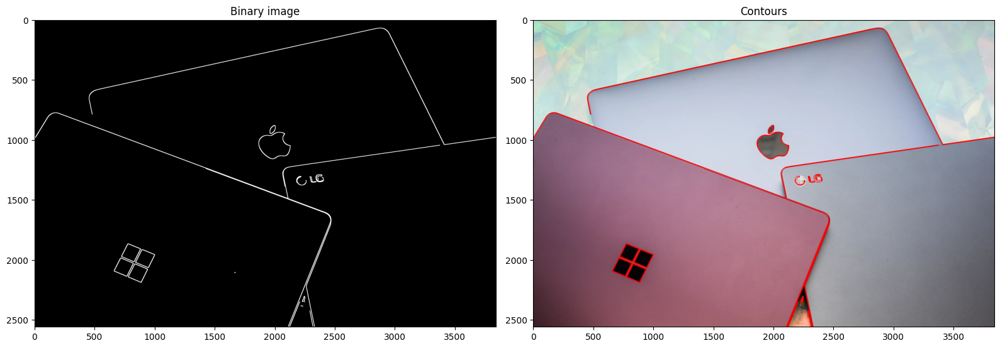

In [19]:
laptop = read_image('laptop')
laptop_gray = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)

binary = cv.Canny(cv.GaussianBlur(laptop_gray, (7, 7), 0), 50, 150)
binary = cv.dilate(binary, cv.getStructuringElement(cv.MORPH_RECT, (5, 5)))

contours, hierarchy = cv.findContours(binary, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
MIN_AREA = 500
contours = [c for c in contours if cv.contourArea(c) > MIN_AREA]
print('contours found (area > %d): %d' % (MIN_AREA, len(contours)))

contour_img = laptop.copy()
cv.drawContours(contour_img, contours, -1, (0, 0, 255), 4)

show_row([binary, contour_img], ['Binary image', 'Contours'], (16, 6))

**Observation (D1.7)** - 20 contours with an area above 500 were found. The red lines follow the outlines of the three laptops and of the logos (Apple, LG, and the four squares of the Microsoft logo); the other contours are small details. `RETR_TREE` gives the inner contours of the logos together with the outer outlines.

**D2 - Feature Matching and Face Detection**

---

**D2.A - Feature matching demo: ORB and SIFT** (`reeses_puffs.png` is searched inside `many_cereals.jpg`)

---

The box in the template is bigger than the one on the shelf, so plain template matching fails. Feature matching compares keypoint descriptors, so the size does not matter much.

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/reeses_puffs.png (560, 560)
read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/many_cereals.jpg (425, 757)


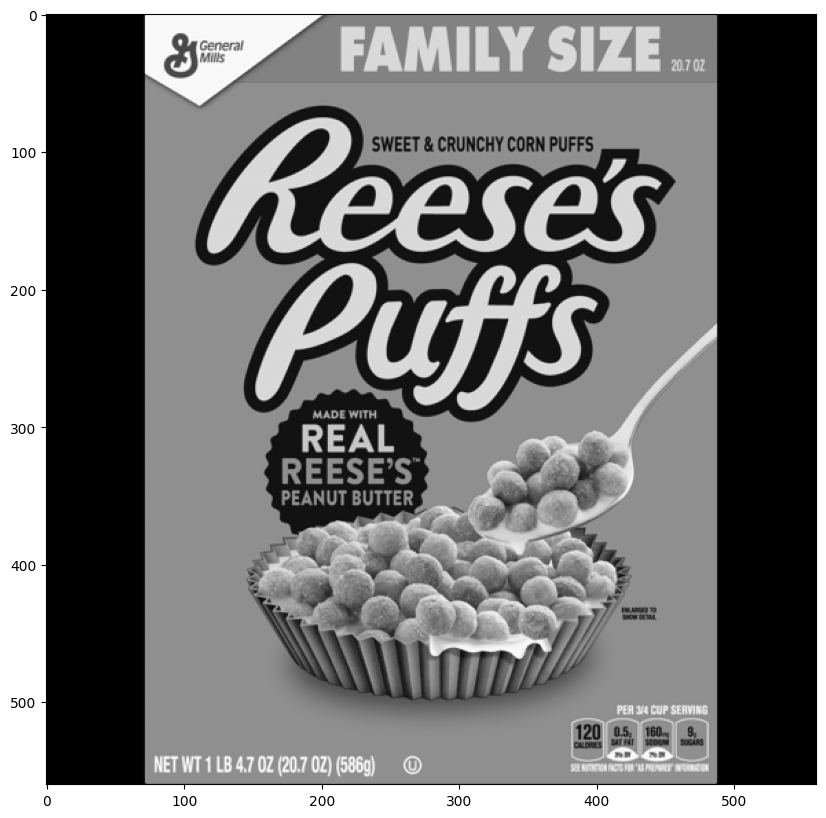

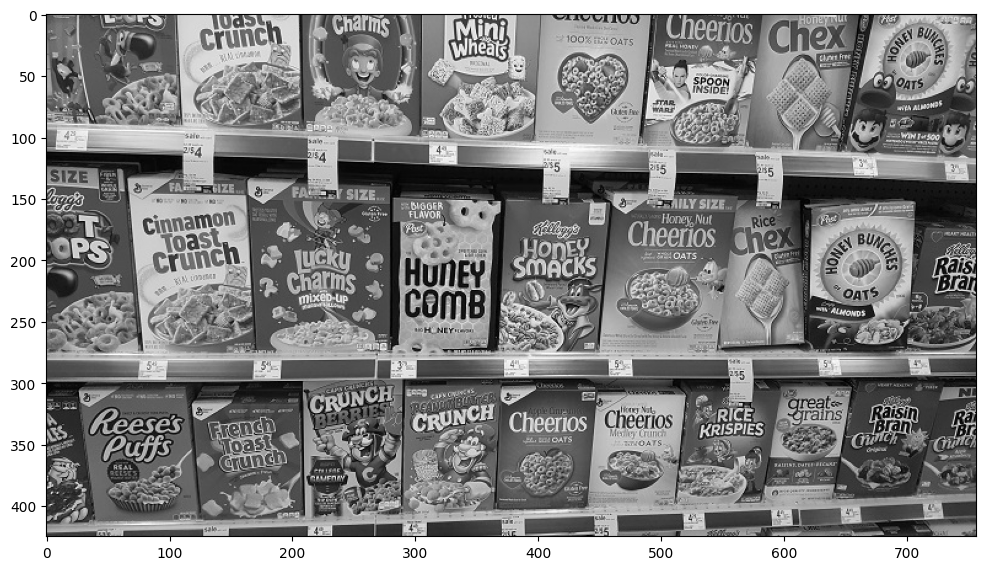

In [20]:
reeses = read_image('reeses_puffs', cv.IMREAD_GRAYSCALE)
cereals = read_image('many_cereals', cv.IMREAD_GRAYSCALE)

def display(img, cmap='gray', figsize=(12, 10)):
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111)
    ax.imshow(img, cmap=cmap)
    plt.show()

display(reeses)
display(cereals)

**ORB + Brute-Force matcher** - Hamming distance, the 25 best matches are drawn.

keypoints: 500 500 | matches: 139 | best distance: 42.0


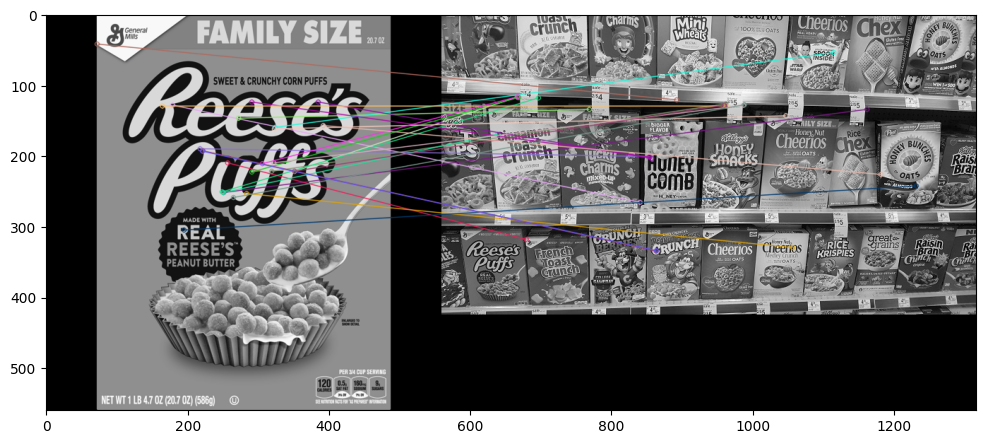

In [21]:
orb = cv.ORB_create()
kp1, des1 = orb.detectAndCompute(reeses, None)
kp2, des2 = orb.detectAndCompute(cereals, None)

bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
print('keypoints:', len(kp1), len(kp2), '| matches:', len(matches), '| best distance:', min(m.distance for m in matches))

matches = sorted(matches, key=lambda x: x.distance)
reeses_match = cv.drawMatches(reeses, kp1, cereals, kp2, matches[:25], None, flags=2)
display(reeses_match)

**SIFT + Brute-Force matcher + ratio test** - a match is kept only if its distance is below 75% of the second best.

matches before the ratio test: 1501 | after: 79


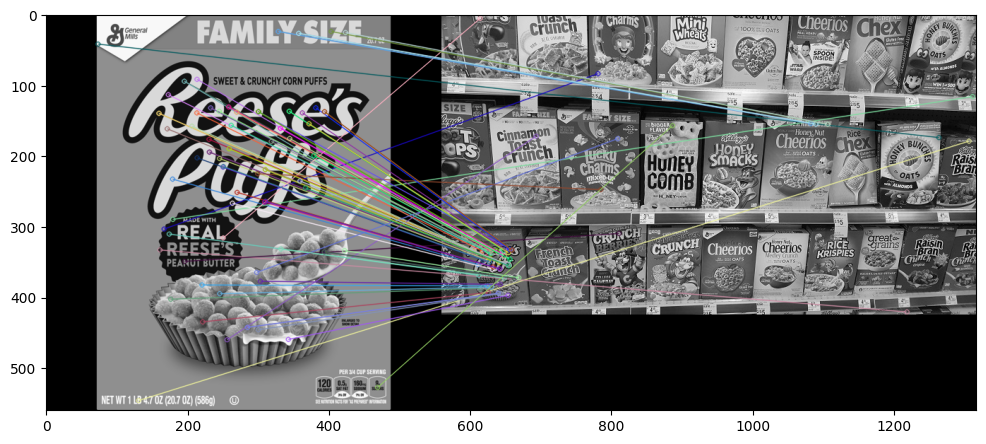

In [22]:
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(reeses, None)
kp2, des2 = sift.detectAndCompute(cereals, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good = []
for match1, match2 in matches:
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])

print('matches before the ratio test:', len(matches), '| after:', len(good))
sift_matches = cv.drawMatchesKnn(reeses, kp1, cereals, kp2, good, None, flags=2)
display(sift_matches)

**Observation (D2.A)** - ORB found 500 keypoints in each image and 139 matches (best distance 42). The 25 best matches go to many places on the shelf and not to the Reese's Puffs box, so the result is not accurate. SIFT had 1501 pairs and 79 after the ratio test, and most lines now end at the Reese's Puffs box on the bottom shelf. SIFT is much better here because it handles the size difference between the two images.

**Helper functions for the face detection tasks**

Cascades are read from `Images/haarcascades`, or from the copy installed with OpenCV if the file is missing. `detectMultiScale()` returns the boxes `(x, y, w, h)`.

In [23]:
def load_cascade(filename):
    path = os.path.join(HAAR, filename)
    if not os.path.isfile(path):
        path = os.path.join(cv.data.haarcascades, filename)
    cascade = cv.CascadeClassifier(path)
    if cascade.empty():
        raise FileNotFoundError('Cascade cannot be loaded: ' + path)
    print('cascade:', path)
    return cascade

def draw_boxes(img, boxes, color=(0, 255, 0), offset=(0, 0)):
    out = img.copy()
    t = max(1, int(round(img.shape[1] / 250)))
    for (x, y, w, h) in boxes:
        cv.rectangle(out, (x + offset[0], y + offset[1]), (x + offset[0] + w, y + offset[1] + h), color, t)
    return out

cascade_face = load_cascade('haarcascade_frontalface_alt.xml')

facedet_files = sorted(f for f in os.listdir(FACEDET) if f.lower().endswith(IMG_EXT))
print('Images in facedet:', facedet_files)

cascade: /content/drive/MyDrive/PCVK Semester 5/Images/haarcascades/haarcascade_frontalface_alt.xml
Images in facedet: ['jokowi.jpg', 'kartini.jpg', 'kucing.jpg', 'many_cereals.jpg', 'mask.png', 'mjordan.jpg', 'reeses_puffs.png', 'solvayconf.jpg']


**D2.8 - Face detection for all the images in `/images/facedet`**

---

Every image except the cereal and `people` images is shown before and after the detection.

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/jokowi.jpg (1050, 873, 3)
jokowi.jpg                   faces: 1


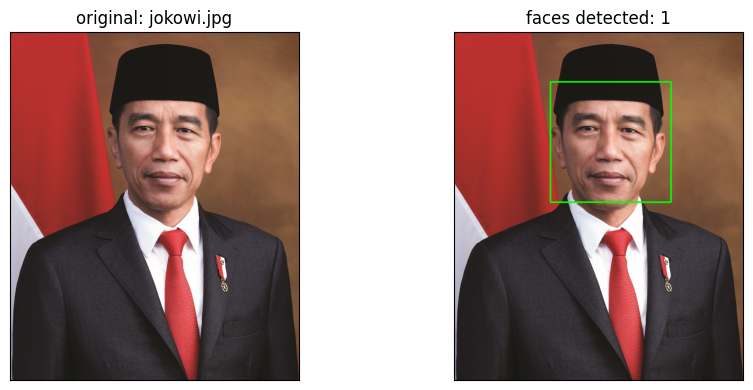

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/kartini.jpg (700, 534, 3)
kartini.jpg                  faces: 1


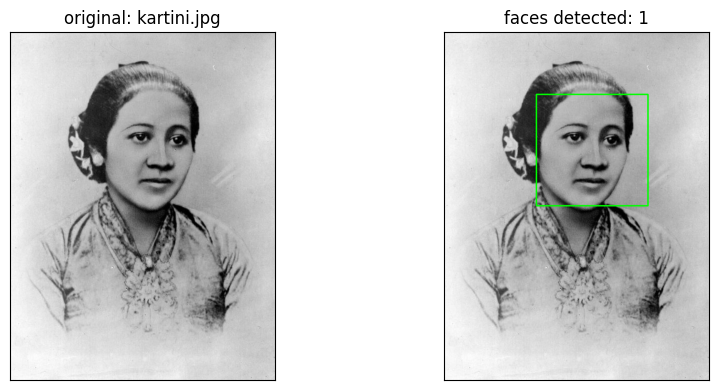

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/kucing.jpg (534, 890, 3)
kucing.jpg                   faces: 0


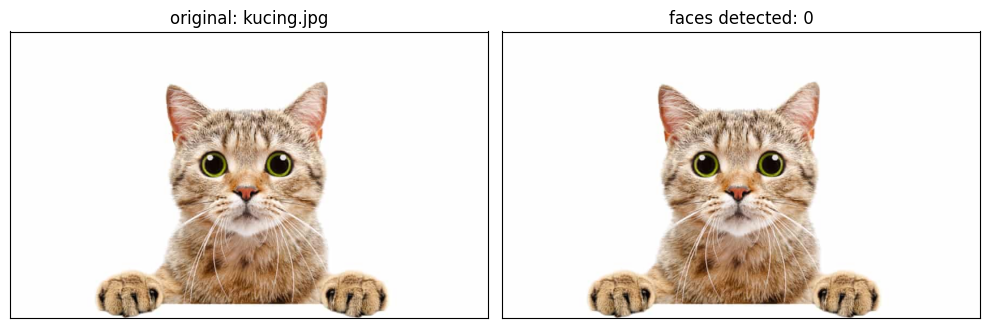

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/mask.png (480, 726, 3)
mask.png                     faces: 5


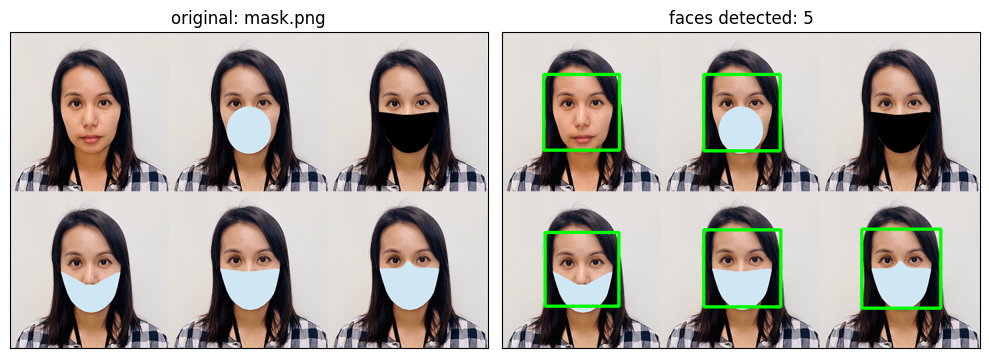

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/mjordan.jpg (568, 398, 3)
mjordan.jpg                  faces: 1


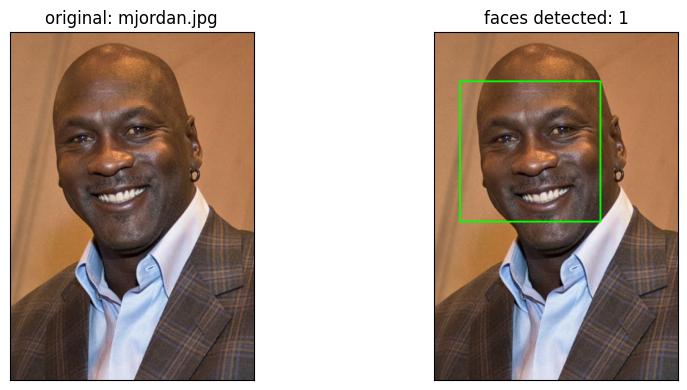

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/solvayconf.jpg (760, 1050, 3)
solvayconf.jpg               faces: 28


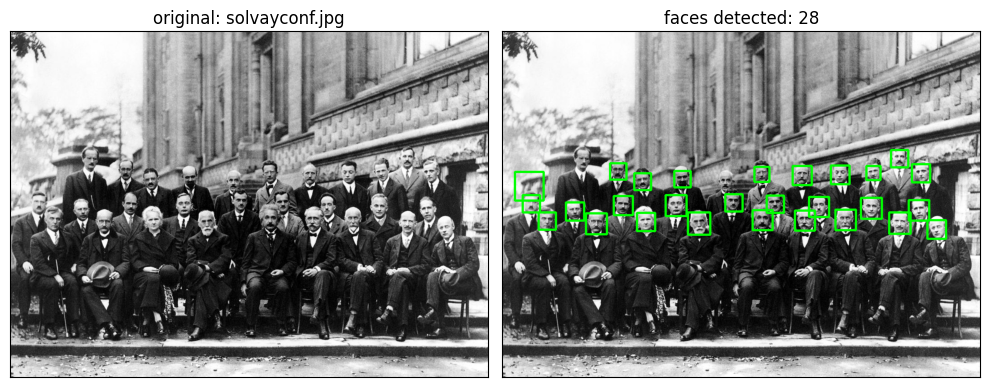

In [24]:
SKIP = ('reeses', 'cereal', 'people')
SCALE_FACTOR, MIN_NEIGHBORS = 1.1, 3

for f in facedet_files:
    if any(s in f.lower() for s in SKIP):
        continue
    img = read_image(os.path.join(FACEDET, f))
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    faces = cascade_face.detectMultiScale(gray, scaleFactor=SCALE_FACTOR, minNeighbors=MIN_NEIGHBORS)
    print('%-28s faces: %d' % (f, len(faces)))
    show_row([img, draw_boxes(img, faces)], ['original: ' + f, 'faces detected: %d' % len(faces)], (10, 4), axis=False)

**Observation (D2.8)** - jokowi: 1 face, kartini: 1 face (an old photograph also works), kucing: 0 faces (a cat is not a human face), mask: 5 of 6 faces (only the face with the black mask is missed), mjordan: 1 face, solvayconf: 28 small faces. Frontal faces are detected well, also with white masks, but not the cat and not the black mask.

**D2.9 - Cat face detection**

---

The human face cascade does not detect a cat. The cascades `haarcascade_frontalcatface.xml` and `haarcascade_frontalcatface_extended.xml` are trained on cat faces.

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/kucing.jpg (534, 890, 3)
cascade: /content/drive/MyDrive/PCVK Semester 5/Images/haarcascades/haarcascade_frontalcatface.xml
human face cascade on the cat: 0 | cat face cascade: 2


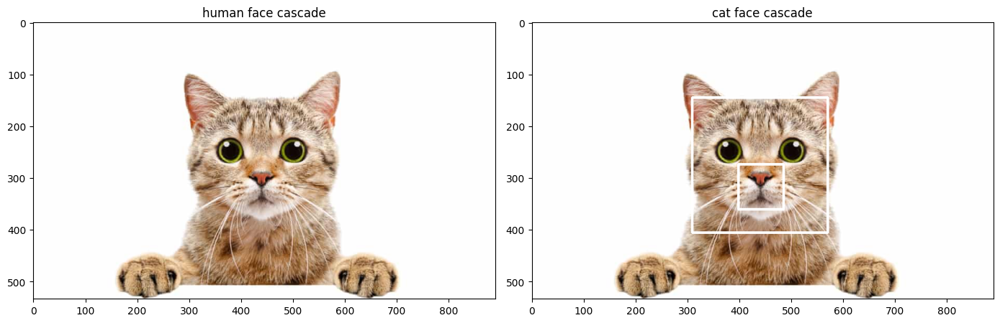

In [25]:
cat = read_image('kucing', folder=FACEDET)
cat_gray = cv.cvtColor(cat, cv.COLOR_BGR2GRAY)

human_on_cat = cascade_face.detectMultiScale(cat_gray, 1.1, 3)

cascade_cat = load_cascade('haarcascade_frontalcatface.xml')
cat_faces = cascade_cat.detectMultiScale(cat_gray, scaleFactor=1.1, minNeighbors=3, minSize=(75, 75))

if len(cat_faces) == 0:
    cascade_cat = load_cascade('haarcascade_frontalcatface_extended.xml')
    cat_faces = cascade_cat.detectMultiScale(cat_gray, scaleFactor=1.1, minNeighbors=3, minSize=(75, 75))

print('human face cascade on the cat:', len(human_on_cat), '| cat face cascade:', len(cat_faces))
show_row([draw_boxes(cat, human_on_cat, (255, 255, 255)), draw_boxes(cat, cat_faces, (255, 255, 255))],
         ['human face cascade', 'cat face cascade'], (14, 5))

**Observation (D2.9)** - The human face cascade finds 0 faces on the cat. The cat face cascade finds 2 boxes: a large one on the whole head and a small one on the nose, so the small one is a false detection. Keeping only the biggest box, or a higher `minNeighbors`, gives the single rectangle.

**D2.10 - Eye detection on the face of Pak Prabowo**

---

Eyes are searched only inside the detected face, and the positions are shifted back by `(x, y)` of the face.

read: /content/drive/MyDrive/PCVK Semester 5/Images/prabowo.jpg (252, 200, 3)
cascade: /content/drive/MyDrive/PCVK Semester 5/Images/haarcascades/haarcascade_eye.xml
face at (np.int32(83), np.int32(44), np.int32(77), np.int32(77)) -> eyes: 1


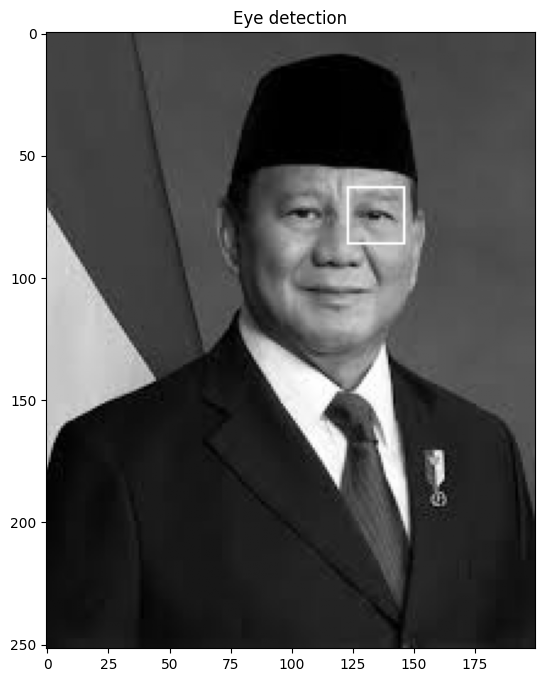

In [26]:
prabowo = read_image('prabowo')
prabowo_gray = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)
cascade_eye = load_cascade('haarcascade_eye.xml')

result = prabowo_gray.copy()
for (x, y, w, h) in cascade_face.detectMultiScale(prabowo_gray, 1.1, 3):
    roi = prabowo_gray[y:y + h, x:x + w]
    eyes = cascade_eye.detectMultiScale(roi)
    print('face at', (x, y, w, h), '-> eyes:', len(eyes))
    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(result, (x + ex, y + ey), (x + ex + ew, y + ey + eh), 255, 1)

plt.figure(figsize=(7, 8))
plt.imshow(result, 'gray')
plt.title('Eye detection')
plt.show()

**Observation (D2.10)** - One face was found at (83, 44) with a size of 77 x 77, and only 1 eye was detected inside it, the one on the right side of the image. The other eye is missed, probably because the image is small (252 x 200) and that eye is in shadow. A smaller `scaleFactor` (1.05) or `minNeighbors` may find both.

**D2.11 - Smile detection on the `people` image**

---

A smile is searched in the lower half of each face. `minNeighbors` is high to avoid false smiles.

read: /content/drive/MyDrive/PCVK Semester 5/people.png (798, 1612, 3)
cascade: /content/drive/MyDrive/PCVK Semester 5/Images/haarcascades/haarcascade_smile.xml
faces: 9 | smiles: 3


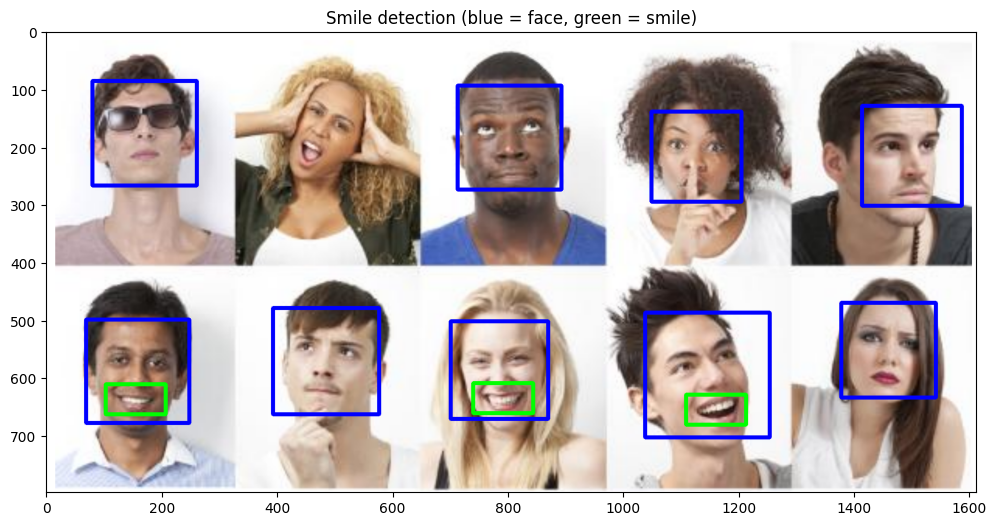

In [27]:
people = read_image('/content/drive/MyDrive/PCVK Semester 5/people.png')
people_gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
cascade_smile = load_cascade('haarcascade_smile.xml')

SMILE_SCALE, SMILE_NEIGHBORS = 1.7, 20

result = people.copy()
t = max(1, int(round(people.shape[1] / 250)))
n_faces = n_smiles = 0
for (x, y, w, h) in cascade_face.detectMultiScale(people_gray, 1.1, 3):
    n_faces += 1
    cv.rectangle(result, (x, y), (x + w, y + h), (255, 0, 0), t)
    roi = people_gray[y + h // 2:y + h, x:x + w]
    for (sx, sy, sw, sh) in cascade_smile.detectMultiScale(roi, SMILE_SCALE, SMILE_NEIGHBORS):
        n_smiles += 1
        cv.rectangle(result, (x + sx, y + h // 2 + sy), (x + sx + sw, y + h // 2 + sy + sh), (0, 255, 0), t)

print('faces:', n_faces, '| smiles:', n_smiles)
plt.figure(figsize=(12, 7))
plt.imshow(to_rgb(result))
plt.title('Smile detection (blue = face, green = smile)')
plt.show()

**Observation (D2.11)** - 9 of the 10 faces were detected (the woman with her hands on her head is missed) and 3 smiles were found. The 3 smiles are on the 3 people in the bottom row who smile with their teeth, and no other face is marked, so there is no false smile.

**D2.12 - Face tracking with the camera in Google Colab**

---

Colab cannot open the laptop camera directly, so JavaScript reads the browser camera and Python detects the faces in every frame. Run the last cell, allow the camera, and click the video to stop. It works only in Colab with a camera.

In [28]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import io
from PIL import Image as PILImage

def js_to_image(js_reply):
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv.imdecode(jpg_as_np, flags=1)

def bbox_to_bytes(bbox_array):
    bbox_pil = PILImage.fromarray(bbox_array)
    iobuf = io.BytesIO()
    bbox_pil.save(iobuf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(iobuf.getvalue()), 'utf-8'))

def video_stream():
    js = Javascript('''
    var video; var div = null; var stream; var captureCanvas; var imgElement; var labelElement;
    var pendingResolve = null; var shutdown = false;

    function removeDom() {
        stream.getVideoTracks()[0].stop();
        video.remove(); div.remove();
        video = null; div = null; stream = null; imgElement = null; captureCanvas = null; labelElement = null;
    }

    function onAnimationFrame() {
        if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
        if (pendingResolve) {
            var result = "";
            if (!shutdown) {
                captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
                result = captureCanvas.toDataURL('image/jpeg', 0.8);
            }
            var lp = pendingResolve; pendingResolve = null; lp(result);
        }
    }

    async function createDom() {
        if (div !== null) { return stream; }
        div = document.createElement('div');
        div.style.border = '2px solid black'; div.style.padding = '3px';
        div.style.width = '100%'; div.style.maxWidth = '600px';
        document.body.appendChild(div);

        const modelOut = document.createElement('div');
        modelOut.innerHTML = "<span>Status:</span>";
        labelElement = document.createElement('span');
        labelElement.innerText = 'No data'; labelElement.style.fontWeight = 'bold';
        modelOut.appendChild(labelElement); div.appendChild(modelOut);

        video = document.createElement('video');
        video.style.display = 'block'; video.width = div.clientWidth - 6;
        video.setAttribute('playsinline', '');
        video.onclick = () => { shutdown = true; };
        stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});
        div.appendChild(video);

        imgElement = document.createElement('img');
        imgElement.style.position = 'absolute'; imgElement.style.zIndex = 1;
        imgElement.onclick = () => { shutdown = true; };
        div.appendChild(imgElement);

        const instruction = document.createElement('div');
        instruction.innerHTML = '<span style="color: red; font-weight: bold;">Click here or on the video to stop</span>';
        div.appendChild(instruction);
        instruction.onclick = () => { shutdown = true; };

        video.srcObject = stream;
        await video.play();

        captureCanvas = document.createElement('canvas');
        captureCanvas.width = 640; captureCanvas.height = 480;
        window.requestAnimationFrame(onAnimationFrame);
        return stream;
    }

    async function stream_frame(label, imgData) {
        if (shutdown) { removeDom(); shutdown = false; return ''; }
        stream = await createDom();
        if (label != "") { labelElement.innerHTML = label; }
        if (imgData != "") {
            var videoRect = video.getClientRects()[0];
            imgElement.style.top = videoRect.top + "px"; imgElement.style.left = videoRect.left + "px";
            imgElement.style.width = videoRect.width + "px"; imgElement.style.height = videoRect.height + "px";
            imgElement.src = imgData;
        }
        var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
        shutdown = false;
        return {'img': result};
    }
    ''')
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

In [29]:
video_stream()
label_html = 'Capturing...'
bbox = ''

while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break
    frame = js_to_image(js_reply['img'])
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    faces = cascade_face.detectMultiScale(gray, 1.1, 3)

    bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
    for (x, y, w, h) in faces:
        cv.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0), 2)
    bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(np.uint8) * 255
    bbox = bbox_to_bytes(bbox_array)
    label_html = 'Faces: %d' % len(faces)

<IPython.core.display.Javascript object>

MessageError: NotAllowedError: Permission denied

**Observation (D2.12)** - The live camera view is not saved in the notebook. A rectangle follows every face in real time and the status line shows the number of faces.

**D2.13 - Blurring the detected faces**

---

The face area is cut out, blurred with `cv.medianBlur()` (odd kernel, a fraction of the face width) and put back.

read: /content/drive/MyDrive/PCVK Semester 5/Images/facedet/mjordan.jpg (568, 398, 3)
faces blurred: 1


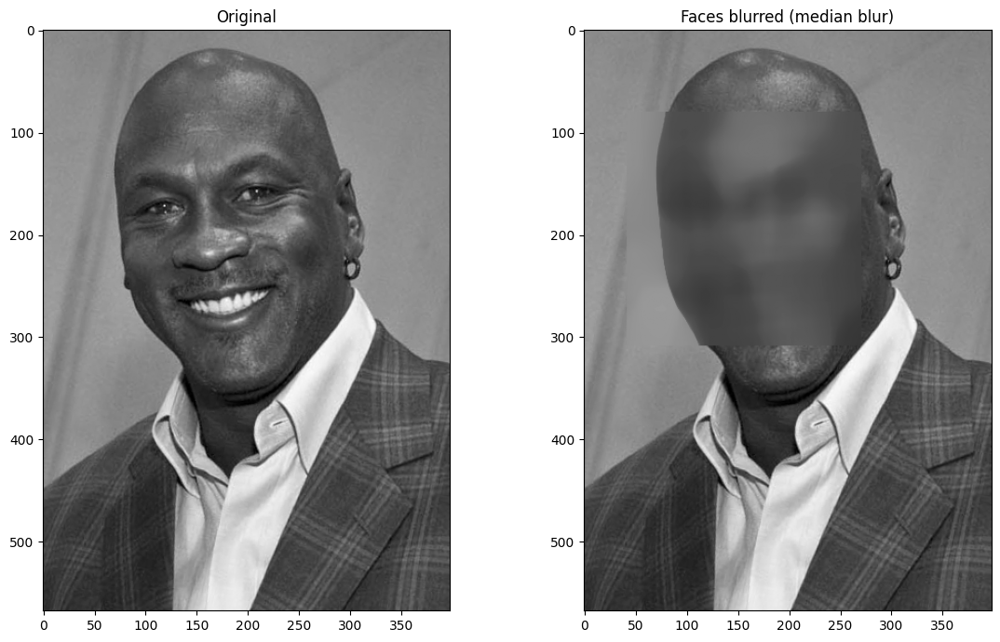

In [30]:
BLUR_IMAGE = 'jordan'

blur_src = read_image(BLUR_IMAGE, folder=FACEDET)
blur_gray = cv.cvtColor(blur_src, cv.COLOR_BGR2GRAY)

blurred = blur_gray.copy()
faces = cascade_face.detectMultiScale(blur_gray, 1.1, 3)
for (x, y, w, h) in faces:
    k = (w // 4) | 1
    blurred[y:y + h, x:x + w] = cv.medianBlur(blurred[y:y + h, x:x + w], k)
print('faces blurred:', len(faces))

show_row([blur_gray, blurred], ['Original', 'Faces blurred (median blur)'], (12, 7))

**Observation (D2.13)** - 1 face was found and the box from forehead to chin is blurred, so the eyes, nose and mouth cannot be recognised. The rest of the image is unchanged. The blur has a rectangular edge, because the whole detected box is blurred.

**D2.14 - Processing the KTM (student ID card)**

---

Set `KTM_NAME` and `SCENE_NAME` to your KTM photo and to a photo with the KTM and other objects (a name or a full path).

In [31]:
KTM_NAME = '/content/drive/MyDrive/PCVK Semester 5/KTM Zid.jpg'
SCENE_NAME = '/content/drive/MyDrive/PCVK Semester 5/ktm_scene.jpg'

ktm = read_image(KTM_NAME)
ktm_gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)

read: /content/drive/MyDrive/PCVK Semester 5/KTM Zid.jpg (1200, 1600, 3)


**a. The KTM**

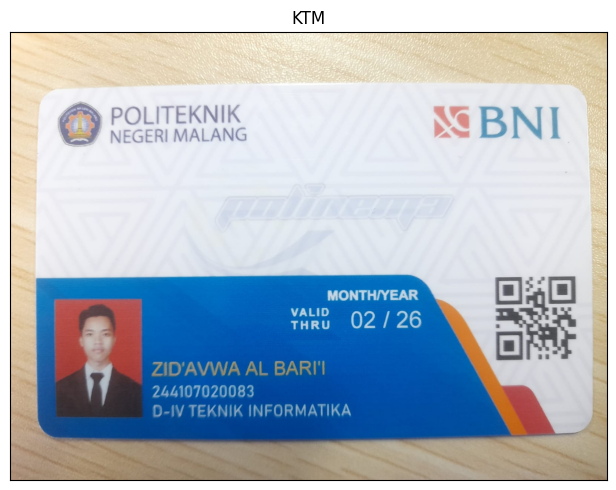

In [32]:
show_row([ktm], ['KTM'], (8, 5), axis=False)

**b. The KTM photo** - the biggest detected face is used, and its box is enlarged before cropping.

faces found in the KTM: 2


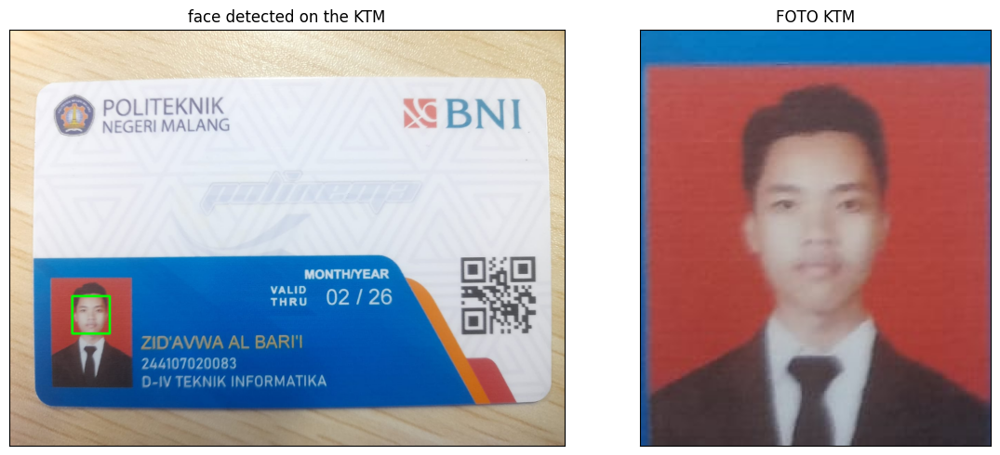

In [33]:
faces = cascade_face.detectMultiScale(ktm_gray, 1.05, 3, minSize=(30, 30))
print('faces found in the KTM:', len(faces))

if len(faces) == 0:
    print('No face found. Lower minNeighbors or minSize, or use a sharper photo of the KTM.')
else:
    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    x0, x1 = max(0, int(x - 0.6 * w)), min(ktm.shape[1], int(x + 1.6 * w))
    y0, y1 = max(0, int(y - 0.7 * h)), min(ktm.shape[0], int(y + 1.9 * h))
    ktm_photo = ktm[y0:y1, x0:x1]

    marked = draw_boxes(ktm, [(x, y, w, h)])
    show_row([marked, ktm_photo], ['face detected on the KTM', 'FOTO KTM'], (12, 5), axis=False)

**c. Find the KTM in the scene** - SIFT matches (ratio test 0.75), then a RANSAC homography gives the four corners of the KTM.

read: /content/drive/MyDrive/PCVK Semester 5/ktm_scene.jpg (2976, 3968, 3)
keypoints (KTM, scene): 3036 31902 | good matches: 570
inliers (RANSAC): 408 of 570


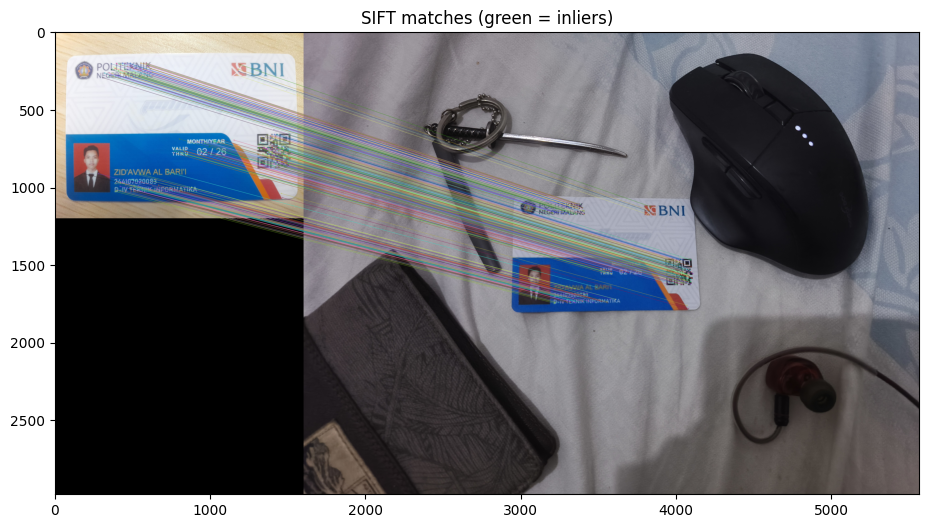

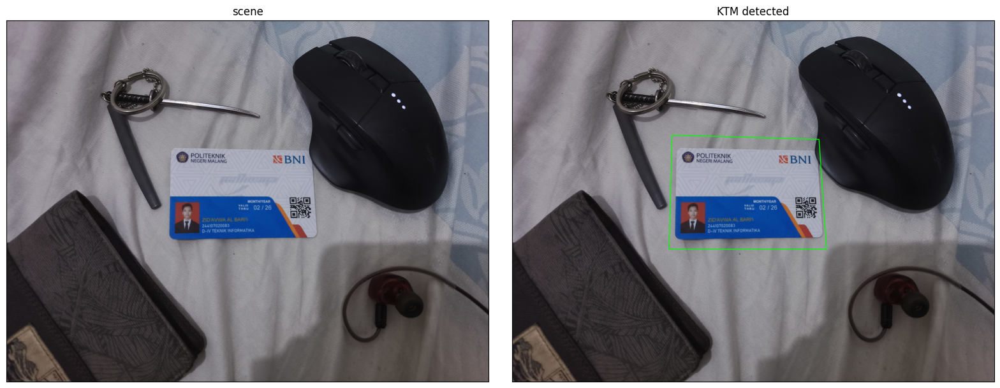

In [34]:
scene = read_image(SCENE_NAME)
scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp_o, des_o = sift.detectAndCompute(ktm_gray, None)
kp_s, des_s = sift.detectAndCompute(scene_gray, None)

pairs = cv.BFMatcher().knnMatch(des_o, des_s, k=2)
good = [m for m, n in (p for p in pairs if len(p) == 2) if m.distance < 0.75 * n.distance]
print('keypoints (KTM, scene):', len(kp_o), len(kp_s), '| good matches:', len(good))

MIN_MATCHES = 10
result = scene.copy()
mask_list = None
if len(good) >= MIN_MATCHES:
    src_pts = np.float32([kp_o[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_s[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    if H is not None:
        mask_list = mask.ravel().tolist()
        h, w = ktm_gray.shape
        corners = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
        box = cv.perspectiveTransform(corners, H)
        cv.polylines(result, [np.int32(box)], True, (0, 255, 0), 6)
        print('inliers (RANSAC):', int(mask.sum()), 'of', len(good))
else:
    print('Not enough matches (%d < %d): the KTM is not found.' % (len(good), MIN_MATCHES))

matches_img = cv.drawMatches(ktm, kp_o, scene, kp_s, good, None, matchesMask=mask_list, flags=2)
plt.figure(figsize=(16, 6)); plt.imshow(to_rgb(matches_img)); plt.title('SIFT matches (green = inliers)'); plt.show()
show_row([scene, result], ['scene', 'KTM detected'], (16, 6), axis=False)

**Observation (D2.14)** - Two faces were found in the KTM; the biggest one is the photo and it is cropped correctly. SIFT found 3036 keypoints in the KTM and 31902 in the scene, 570 good matches, and 408 inliers after RANSAC. The green box lands on the KTM in the scene, but it is a little loose and tilted because some matches are not exact.

**D3 - Enrichment task: character recognition on the KTM with a CNN**

---

Four steps: (1) training images, one folder per character; (2) convert them to arrays; (3) train and save the CNN; (4) cut the characters out of the KTM and recognise them.

```
dataset/
  training/   0/ 1/ ... 9/
  testing/    KTM/ 00.png 01.png ...
```

**Step 1 - Check the folders**

In [35]:
DATASET = BASE + '/dataset'
DATADIR = DATASET + '/training'
TESTDIR = DATASET + '/testing'
width, height = 100, 100

if not os.path.isdir(DATADIR):
    raise FileNotFoundError('Put the training images in ' + DATADIR + ' (one sub-folder per character).')
for d in sorted(os.listdir(DATADIR)):
    print('class %-3s images: %d' % (d, len(os.listdir(os.path.join(DATADIR, d)))))

class 0   images: 150
class 1   images: 150
class 2   images: 150
class 3   images: 150
class 4   images: 150
class 5   images: 150
class 6   images: 150
class 7   images: 150
class 8   images: 150
class 9   images: 150


**Step 2 - Prepare the training data** (the pickle files are saved in Drive).

In [36]:
import random
import pickle
from tqdm import tqdm

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv.imread(os.path.join(path, img), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open(DATASET + '/X.pickle', 'wb'))
pickle.dump(Y, open(DATASET + '/Y.pickle', 'wb'))
pickle.dump(dirs, open(DATASET + '/kelas.pickle', 'wb'))

print('number of data :', len(training_data))
print('number of class:', len(dirs), dirs)

9: 100%|██████████| 150/150 [00:01<00:00, 75.63it/s] 


number of data : 1500
number of class: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


**Step 3 - Train the CNN.** Convolution blocks extract the features, dense layers classify, softmax gives one output per class. 20% of the data is kept for validation.

In [37]:
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open(DATASET + '/X.pickle', 'rb'))
Y = pickle.load(open(DATASET + '/Y.pickle', 'rb'))

Y = to_categorical(Y)
X = X / 255.0
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d (ZeroPadding2D)  │ (None, 104, 104, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 16)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28224)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     7,225,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,275,498 (27.75 MB)

 Trainable params: 7,275,498 (27.75 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 27s 618ms/step - accuracy: 0.6892 - loss: 1.4637 - val_accuracy: 0.9700 - val_loss: 0.2638
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 23s 606ms/step - accuracy: 0.9867 - loss: 0.0785 - val_accuracy: 0.9933 - val_loss: 0.0276
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 541ms/step - accuracy: 0.9992 - loss: 0.0116 - val_accuracy: 0.9967 - val_loss: 0.0128
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 21s 542ms/step - accuracy: 0.9983 - loss: 0.0068 - val_accuracy: 0.9967 - val_loss: 0.0122
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 580ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 0.0048
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 541ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.9967 - val_loss: 0.0065
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 593ms/step - accuracy: 1.0000 - loss: 6.9251e-04 - val_accuracy: 0.9967 - val_loss: 0.0048
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 530ms/step - accuracy: 1.0000 - loss: 4.8464e-04 - 

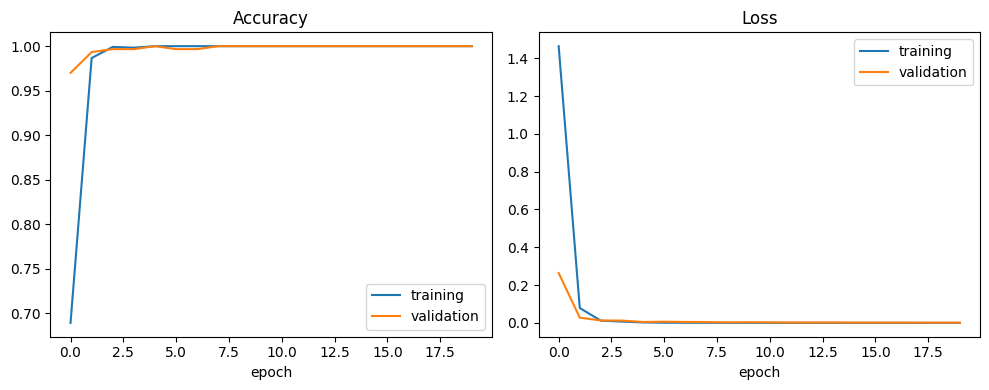

(None, None)

In [38]:
riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save(DATASET + '/anpr.keras')

print('training accuracy  :', riwayat.history['accuracy'][-1])
print('validation accuracy:', riwayat.history['val_accuracy'][-1])

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.plot(riwayat.history['accuracy'], label='training'), plt.plot(riwayat.history['val_accuracy'], label='validation')
plt.title('Accuracy'), plt.xlabel('epoch'), plt.legend()
plt.subplot(122), plt.plot(riwayat.history['loss'], label='training'), plt.plot(riwayat.history['val_loss'], label='validation')
plt.title('Loss'), plt.xlabel('epoch'), plt.legend()
plt.tight_layout(), plt.show()

**Step 4a - Cut the characters out of the KTM.** `NIM_ROI = (x, y, w, h)` marks the NIM line. Otsu separates the text, each contour is one character, sorted from left to right and saved in `dataset/testing/KTM`.

read: /content/drive/MyDrive/PCVK Semester 5/KTM Zid.jpg (1200, 1600, 3)


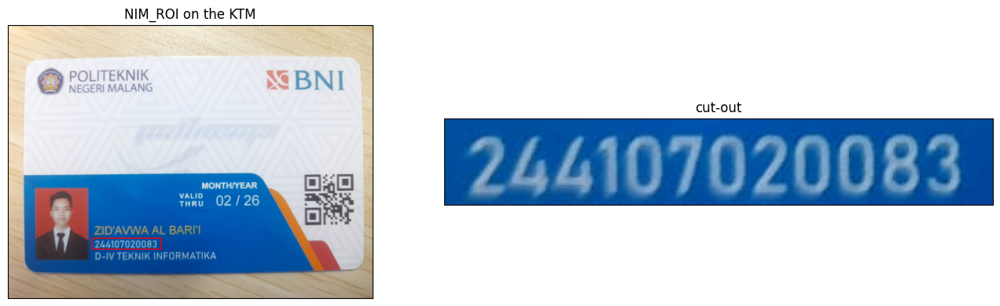

In [39]:
KTM_NAME = '/content/drive/MyDrive/PCVK Semester 5/KTM Zid.jpg'
ktm = read_image(KTM_NAME)
ktm_gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)

H_img, W_img = ktm_gray.shape
NIM_ROI = (int(0.23 * W_img), int(0.78 * H_img), int(0.19 * W_img), int(0.04 * H_img))

x, y, w, h = NIM_ROI
preview = ktm.copy()
cv.rectangle(preview, (x, y), (x + w, y + h), (0, 0, 255), 3)
show_row([preview, ktm[y:y + h, x:x + w]], ['NIM_ROI on the KTM', 'cut-out'], (14, 4), axis=False)

characters found: 12


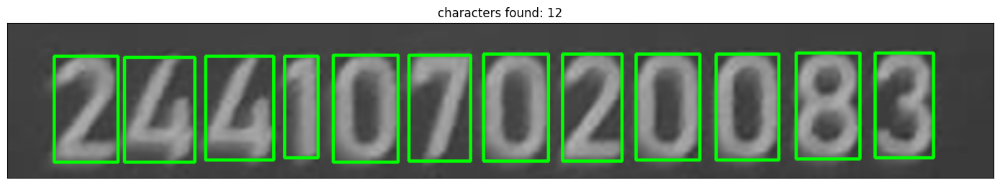

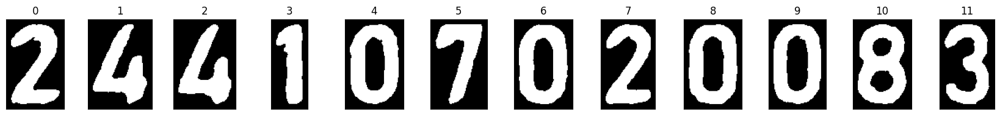

In [40]:
roi = ktm_gray[y:y + h, x:x + w]
roi = cv.resize(roi, None, fx=3, fy=3, interpolation=cv.INTER_CUBIC)
roi = cv.GaussianBlur(roi, (3, 3), 0)

_, mask = cv.threshold(roi, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
if mask.mean() > 127:
    mask = cv.bitwise_not(mask)

contours, _ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
boxes = [cv.boundingRect(c) for c in contours]
boxes = [b for b in boxes if b[3] > 0.4 * roi.shape[0] and b[2] > 0.02 * roi.shape[1]]
boxes = sorted(boxes, key=lambda b: b[0])
print('characters found:', len(boxes))

out_dir = TESTDIR + '/KTM'
os.makedirs(out_dir, exist_ok=True)
for f in os.listdir(out_dir):
    os.remove(os.path.join(out_dir, f))

marked = cv.cvtColor(roi, cv.COLOR_GRAY2BGR)
crops = []
for i, (bx, by, bw, bh) in enumerate(boxes):
    pad = 6
    crop = mask[max(0, by - pad):by + bh + pad, max(0, bx - pad):bx + bw + pad]
    cv.imwrite('%s/%02d.png' % (out_dir, i), crop)
    crops.append(crop)
    cv.rectangle(marked, (bx, by), (bx + bw, by + bh), (0, 255, 0), 2)

show_row([marked], ['characters found: %d' % len(boxes)], (14, 3), axis=False)
if crops:
    show_row(crops, [str(i) for i in range(len(crops))], (1.4 * len(crops), 2), axis=False)

Training images and cut characters must have the same polarity (white on black or black on white). Use `cv.bitwise_not()` if they differ.

**Step 4b - Recognise the characters** (testing code of the module).

In [41]:
import tensorflow as tf

model = tf.keras.models.load_model(DATASET + '/anpr.keras')
dirs = pickle.load(open(DATASET + '/kelas.pickle', 'rb'))

for car in sorted(os.listdir(TESTDIR)):
    temp = ''
    folder = os.path.join(TESTDIR, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print('folder name: {} no: {}'.format(car, temp))

folder name: KTM no: 244107020083


**Observation (D3)** - Training and validation accuracy reach 1.0 (loss about 0.0015) after a few epochs. This is expected for the generated digit dataset, so it does not prove that the model reads real photos. Step 4a found 12 characters and step 4b read `244107020083`, which is exactly the NIM on the KTM (12 of 12 correct).